# Classification and Evaluation in NLP

Name : Maan A. Alghamdi  
ID : 2240001433

**Text classification** is a common Natural Language Processing (NLP) task where a model assigns a predefined category or label to a piece of text.

Examples include:
- Spam detection
- Sentiment analysis
- News categorization

In this lab, we will learn how to build and evaluate a text classification model.

## Case Study: Sentiment Analysis

Sentiment analysis, also known as opinion mining, its goal is to understand the information present in the text and categorize it as positive, negative, or neutral.

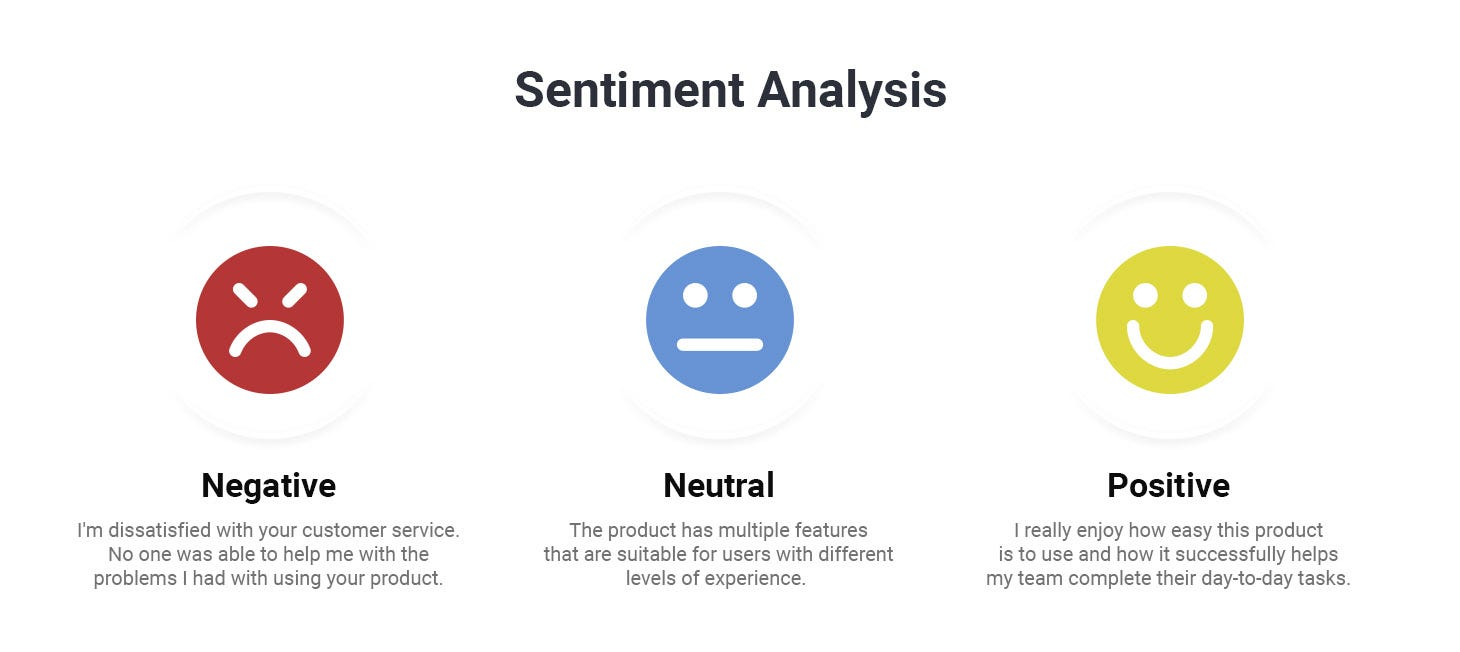

# Disneyland Reviews Dataset
In this lab we'll look into Disneyland Reviews dataset.  
*Link: https://www.kaggle.com/datasets/arushchillar/disneyland-reviews*

The dataset includes 42,000 reviews of 3 Disneyland branches - Paris, California and Hong Kong, posted by visitors on Trip Advisor.

Column Description:

- Review_ID: unique id given to each review
- Rating: ranging from 1 (unsatisfied) to 5 (satisfied)
- Year_Month: when the reviewer visited the theme park
- Reviewer_Location: country of origin of visitor
- Review_Text: comments made by visitor
- Disneyland_Branch: location of Disneyland Park

**Provided example:** The Disneyland cells below are the original worked example and require `DisneylandReviews.csv` in `/content/`. Their original outputs are retained. The completed Amazon exercise below is independent; run it starting at Task 1.

In [1]:
# Load the dataset
import pandas as pd

data = pd.read_csv('DisneylandReviews.csv', encoding='latin-1')
data

,Review_ID,Rating,Year_Month,Reviewer_Location,Review_Text,Branch
0,670772142,4,2019-4,Australia,If you've ever been to Disneyland anywhere you...,Disneyland_HongKong
1,670682799,4,2019-5,Philippines,Its been a while since d last time we visit HK...,Disneyland_HongKong
2,670623270,4,2019-4,United Arab Emirates,Thanks God it wasn t too hot or too humid wh...,Disneyland_HongKong
3,670607911,4,2019-4,Australia,HK Disneyland is a great compact park. Unfortu...,Disneyland_HongKong
4,670607296,4,2019-4,United Kingdom,"the location is not in the city, took around 1...",Disneyland_HongKong
...,...,...,...,...,...,...
42651,1765031,5,missing,United Kingdom,i went to disneyland paris in july 03 and thou...,Disneyland_Paris
42652,1659553,5,missing,Canada,2 adults and 1 child of 11 visited Disneyland ...,Disneyland_Paris
42653,1645894,5,missing,South Africa,My eleven year old daughter and myself went to...,Disneyland_Paris
42654,1618637,4,missing,United States,"This hotel, part of the Disneyland Paris compl...",Disneyland_Paris


In [2]:
#Check for missing values
data.isna().sum()

Review_ID            0
Rating               0
Year_Month           0
Reviewer_Location    0
Review_Text          0
Branch               0
dtype: int64

In [3]:
# Drop rows with missing values in the relevant columns
data = data.dropna(subset=['Review_Text', 'Rating'])

In [4]:
# Map star ratings to sentiments
data['Sentiment'] = data['Rating'].apply(lambda rating: 'positive' if rating > 3 else ('negative' if rating < 3 else 'neutral'))
data.head()

,Review_ID,Rating,Year_Month,Reviewer_Location,Review_Text,Branch,Sentiment
0,670772142,4,2019-4,Australia,If you've ever been to Disneyland anywhere you...,Disneyland_HongKong,positive
1,670682799,4,2019-5,Philippines,Its been a while since d last time we visit HK...,Disneyland_HongKong,positive
2,670623270,4,2019-4,United Arab Emirates,Thanks God it wasn t too hot or too humid wh...,Disneyland_HongKong,positive
3,670607911,4,2019-4,Australia,HK Disneyland is a great compact park. Unfortu...,Disneyland_HongKong,positive
4,670607296,4,2019-4,United Kingdom,"the location is not in the city, took around 1...",Disneyland_HongKong,positive


In [5]:
# Import necessary libraries
import re
import nltk

def preprocess_text(text):

    # 1. Convert text to lowercase
    text = text.lower()

    # 2. Remove punctuation and special characters
    text = re.sub(r'[^a-z\s]', '', text)

    # 3. Tokenize the text
    words = text.split()

    return ' '.join(words)

# Apply preprocessing to the review text
data['Review_Text'] = data['Review_Text'].apply(preprocess_text)

# Display cleaned reviews
data[['Review_Text', 'Sentiment']].head()

,Review_Text,Sentiment
0,if youve ever been to disneyland anywhere youl...,positive
1,its been a while since d last time we visit hk...,positive
2,thanks god it wasn t too hot or too humid when...,positive
3,hk disneyland is a great compact park unfortun...,positive
4,the location is not in the city took around ho...,positive


In [6]:
# Import necessary libraries
from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer

# Split the dataset into training and testing sets
train_data, test_data, train_labels, test_labels = train_test_split(data['Review_Text'], data['Sentiment'], test_size=0.2, random_state=42)


# TF-IDF Vectorization
tfidf_vectorizer = TfidfVectorizer(max_features=1000)  # You can adjust max_features based on your dataset size - limit vocabulary to the 1000 most informative tokens
train_vectors = tfidf_vectorizer.fit_transform(train_data)
test_vectors = tfidf_vectorizer.transform(test_data)

In [7]:
print(f"train_data size: {train_data.shape}")
print(f"test_data size: {test_data.shape}")

train_data size: (34124,)
test_data size: (8532,)


In [8]:
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score, classification_report

# Train the Support Vector Machine (SVM) classifier
svm_classifier = SVC(kernel='linear')
svm_classifier.fit(train_vectors, train_labels)

# Predictions on the test set
predictions = svm_classifier.predict(test_vectors)

# Evaluate the model
accuracy = accuracy_score(test_labels, predictions)
print(f"Accuracy: {accuracy:.2f}")

# Display classification report
print("Classification Report:")
print(classification_report(test_labels, predictions))


Accuracy: 0.84
Classification Report:
              precision    recall  f1-score   support

    negative       0.64      0.54      0.58       720
     neutral       0.48      0.18      0.26      1035
    positive       0.88      0.98      0.92      6777

    accuracy                           0.84      8532
   macro avg       0.66      0.56      0.59      8532
weighted avg       0.81      0.84      0.81      8532



# Use Case:  Amazon reviews of unlocked phone analysis

The objective of this use case is to conduct sentiment analysis on Amazon reviews of unlocked phones, categorizing reviews into three classes: positive, negative, and neutral. The goal is to gain a comprehensive understanding of customer opinions and sentiments regarding various unlocked phone models.

- Dataset link: https://www.kaggle.com/datasets/PromptCloudHQ/amazon-reviews-unlocked-mobile-phones

Task1: Load the data and do 5 different preprocessing steps on it

Task2: Use a proper train and test split

Task3: Do Feature Extraction Using TF-IDF

Task4: Train a Naive Bayes Classifier

Task5: Evaluate the model on the Test Set

Task6: Print the Confusion Matrix

## Completed solution

Run the following cells in order. Dependencies: `pandas`, `scikit-learn`, and `matplotlib`. Place `Amazon_Unlocked_Mobile.csv` beside this notebook (or upload it to `/content/` in Colab). If it is absent, Task 1 attempts to download the public dataset linked above. Ratings 1–2 are negative, 3 is neutral, and 4–5 are positive.

### Task 1: Load data and apply five preprocessing steps

The five text transformations are: (1) decode HTML entities and remove HTML tags, (2) lowercase, (3) remove URLs, (4) replace punctuation and numbers with spaces, and (5) tokenize and remove stop words, retaining negation words such as “not”. Missing/invalid records and repeated cleaned review texts are also removed before splitting, preventing identical reviews from appearing in both sets.

In [9]:
from pathlib import Path
from urllib.request import urlopen
import zipfile
import io
import html
import re
import pandas as pd
from sklearn.feature_extraction.text import ENGLISH_STOP_WORDS, TfidfVectorizer
from sklearn.model_selection import train_test_split
from sklearn.naive_bayes import MultinomialNB
from sklearn.metrics import (accuracy_score, classification_report, f1_score,
                             confusion_matrix, ConfusionMatrixDisplay)
import matplotlib.pyplot as plt

filename = 'Amazon_Unlocked_Mobile.csv'
candidates = [Path(filename), Path('data') / filename, Path('/content') / filename]
csv_path = next((path for path in candidates if path.is_file()), None)
if csv_path is None:
    dataset_url = ('https://www.kaggle.com/api/v1/datasets/download/'
                   'PromptCloudHQ/amazon-reviews-unlocked-mobile-phones')
    try:
        with urlopen(dataset_url, timeout=120) as response:
            archive_bytes = response.read()
        with zipfile.ZipFile(io.BytesIO(archive_bytes)) as archive:
            member = next(name for name in archive.namelist()
                          if Path(name).name == filename)
            csv_path = Path(filename)
            csv_path.write_bytes(archive.read(member))
    except Exception as error:
        raise RuntimeError('Download Amazon_Unlocked_Mobile.csv from the dataset '
                           'link above, place it beside the notebook, and rerun.') from error

amazon_data = pd.read_csv(csv_path, encoding='utf-8', low_memory=False)
print('Original rows:', len(amazon_data))
print('Missing values in required columns:')
print(amazon_data[['Reviews', 'Rating']].isna().sum())
amazon_data = amazon_data.dropna(subset=['Reviews', 'Rating']).copy()
amazon_data['Rating'] = pd.to_numeric(amazon_data['Rating'], errors='coerce')
amazon_data = amazon_data[amazon_data['Rating'].isin([1, 2, 3, 4, 5])].copy()
amazon_data['Sentiment'] = amazon_data['Rating'].map({
    1: 'negative', 2: 'negative', 3: 'neutral', 4: 'positive', 5: 'positive'
})

stop_words = set(ENGLISH_STOP_WORDS) - {'no', 'nor', 'not', 'never'}

def preprocess_review(text):
    # 1. Decode HTML entities and remove tags.
    text = re.sub(r'<[^>]+>', ' ', html.unescape(str(text)))
    # 2. Convert to lowercase.
    text = text.lower()
    # 3. Remove URLs.
    text = re.sub(r'https?://\S+|www\.\S+', ' ', text)
    # Keep the meaning of common negative contractions before stripping punctuation.
    text = text.replace('’', "'")
    text = text.replace("won't", 'will not').replace("can't", 'can not')
    text = re.sub(r"n['’]t\b", ' not', text)
    # 4. Remove punctuation, numbers, and other non-letter characters.
    text = re.sub(r'[^a-z\s]', ' ', text)
    # 5. Tokenize, remove stop words, and join with normalized whitespace.
    tokens = [word for word in text.split() if word not in stop_words]
    return ' '.join(tokens)

amazon_data['Clean_Review'] = amazon_data['Reviews'].map(preprocess_review)
amazon_data = amazon_data[amazon_data['Clean_Review'].str.len() > 0].copy()
amazon_data = amazon_data.drop_duplicates(subset=['Clean_Review']).reset_index(drop=True)
print('Rows after cleaning and removing duplicate texts:', len(amazon_data))
print('Class counts:')
print(amazon_data['Sentiment'].value_counts())
print('Cleaned examples:')
print(amazon_data[['Clean_Review', 'Sentiment']].head().to_string(index=False))

Original rows: 413840
Missing values in required columns:
Reviews    70
Rating      0
dtype: int64
Rows after cleaning and removing duplicate texts: 152510
Class counts:
Sentiment
positive    95278
negative    43239
neutral     13993
Name: count, dtype: int64
Cleaned examples:
                                                                                                                                                                                           Clean_Review Sentiment
feel lucky used phone not used hard phone line upgraded sold son liked old finally fell apart years did not want upgrade thank seller really appreciate honesty said used phone recommend seller highly  positive
                                                         nice phone nice grade pantach revue clean set easy set never android phone fantastic say perfect size surfing social media great phone samsung  positive
                                                                                            

### Task 2: Train/test split

Use 80% for training and 20% for testing. Stratification preserves the class proportions, and `random_state=42` makes the split reproducible.

In [10]:
X_train, X_test, y_train, y_test = train_test_split(
    amazon_data['Clean_Review'], amazon_data['Sentiment'],
    test_size=0.20, random_state=42, stratify=amazon_data['Sentiment']
)
print('Training reviews:', len(X_train))
print('Test reviews:', len(X_test))
print('Class proportions:')
print(pd.DataFrame({'train': y_train.value_counts(normalize=True),
                    'test': y_test.value_counts(normalize=True)}).round(4))

Training reviews: 122008
Test reviews: 30502
Class proportions:
            train    test
Sentiment                
positive   0.6247  0.6247
negative   0.2835  0.2835
neutral    0.0918  0.0917


### Task 3: TF-IDF feature extraction

Fit TF-IDF only on training reviews to avoid test-set leakage. Unigrams and bigrams capture individual words and short phrases.

In [11]:
vectorizer = TfidfVectorizer(max_features=10000, ngram_range=(1, 2), min_df=2)
X_train_tfidf = vectorizer.fit_transform(X_train)
X_test_tfidf = vectorizer.transform(X_test)
print('Training TF-IDF matrix:', X_train_tfidf.shape)
print('Test TF-IDF matrix:', X_test_tfidf.shape)

Training TF-IDF matrix: (122008, 10000)
Test TF-IDF matrix: (30502, 10000)


### Task 4: Train a Naive Bayes classifier

Multinomial Naive Bayes accepts nonnegative TF-IDF features. Laplace smoothing (`alpha=1.0`) handles unseen feature/class combinations.

In [12]:
nb_classifier = MultinomialNB(alpha=1.0)
nb_classifier.fit(X_train_tfidf, y_train)
print('Trained classifier:', nb_classifier)

Trained classifier: MultinomialNB()


### Task 5: Evaluate on the test set

Report accuracy and per-class precision, recall, and F1. Macro F1 gives each class equal weight, which is useful for this imbalanced dataset. A majority-class baseline provides context for accuracy.

In [13]:
class_labels = ['negative', 'neutral', 'positive']
y_pred = nb_classifier.predict(X_test_tfidf)
test_accuracy = accuracy_score(y_test, y_pred)
macro_f1 = f1_score(y_test, y_pred, average='macro')
majority_class = y_train.value_counts().idxmax()
baseline_accuracy = (y_test == majority_class).mean()
print(f'Test accuracy: {test_accuracy:.4f}')
print(f'Macro F1: {macro_f1:.4f}')
print(f'Majority-class baseline accuracy: {baseline_accuracy:.4f}')
print('Classification report:')
print(classification_report(y_test, y_pred, labels=class_labels,
                            digits=4, zero_division=0))

Test accuracy: 0.8282
Macro F1: 0.5900
Majority-class baseline accuracy: 0.6247
Classification report:
              precision    recall  f1-score   support

    negative     0.7799    0.8148    0.7969      8648
     neutral     0.4021    0.0404    0.0734      2798
    positive     0.8544    0.9499    0.8997     19056

    accuracy                         0.8282     30502
   macro avg     0.6788    0.6017    0.5900     30502
weighted avg     0.7918    0.8282    0.7947     30502



### Task 6: Print the confusion matrix

Rows represent true labels and columns represent predicted labels. Diagonal entries are correct predictions; off-diagonal entries are errors.

Confusion matrix (rows = actual, columns = predicted):
                 Predicted negative  Predicted neutral  Predicted positive
Actual negative                7046                 73                1529
Actual neutral                 1130                113                1555
Actual positive                 859                 95               18102


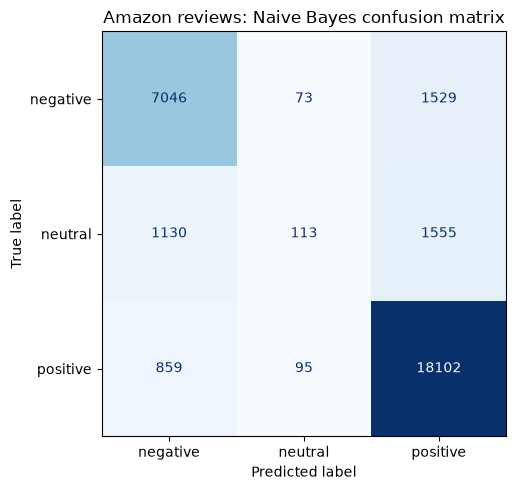

In [14]:
cm = confusion_matrix(y_test, y_pred, labels=class_labels)
print('Confusion matrix (rows = actual, columns = predicted):')
print(pd.DataFrame(cm, index=[f'Actual {label}' for label in class_labels],
                  columns=[f'Predicted {label}' for label in class_labels]).to_string())
fig, ax = plt.subplots(figsize=(7, 5))
ConfusionMatrixDisplay(cm, display_labels=class_labels).plot(
    ax=ax, cmap='Blues', values_format='d', colorbar=False
)
ax.set_title('Amazon reviews: Naive Bayes confusion matrix')
fig.tight_layout()
plt.show()

### Results and interpretation

The held-out test accuracy is **82.82%**, compared with **62.47%** for the majority-class baseline. Macro F1 is **0.5900**. Neutral-class recall is **4.04%**, illustrating why accuracy alone is insufficient: performance differs across sentiment classes. Mixed or ambiguous reviews make the neutral class difficult to recognize. Ratings provide approximate sentiment labels, so some review text may not agree with its assigned label. Any future parameter tuning should use cross-validation within the training set, keeping the test set reserved for final evaluation.